# 01 — Construction du jeu de données de référence

**Projet** : Analyse sémantique et système intelligent de recommandation contextuelle
**Application** : cartographie des compétences et recommandation de profils professionnels
**Groupe** : Alexander, Cyrille, Théophile, Romain — ING5 Data & IA, ECE 2026-27 (Sarah Malaeb)

---

Ce notebook documente **l'origine, la structure et le prétraitement** du référentiel auquel le moteur
compare les réponses des utilisateurs (exigence 2 du sujet).

Le référentiel contient quatre tables :

| Fichier | Contenu | Rôle |
|---|---|---|
| `data/blocs.csv` | 8 blocs de compétences | catégories thématiques (axes du radar) |
| `data/competences.csv` | 71 compétences, chacune avec une description en langage naturel et des mots-clés | cibles sémantiques comparées aux phrases de l'utilisateur |
| `data/metiers.csv` | 12 métiers, avec leurs compétences cœur et secondaires | éléments recommandés |
| `data/outils.csv` | 33 outils (cases à cocher), chacun associé à une phrase d'usage | transforme une case cochée en preuve textuelle |

**Plan**

1. Source : le ROME 4.0 de France Travail
2. Du ROME brut au référentiel : filtrage, regroupement, enrichissement
3. Structure du référentiel et relations métiers ↔ compétences
4. Traçabilité vers le ROME
5. Vérification : les blocs sont-ils sémantiquement cohérents ? (clustering)
6. Prétraitement des textes

In [1]:
# --- Mise en place : chemins, bibliothèques et style des graphiques ---
import sys, warnings, os
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

RACINE = Path.cwd().parent            # le notebook est dans notebooks/, le code dans src/
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# Palette catégorielle (ordre fixe, validée pour le daltonisme) et couleurs d'encre
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT, VIOLET, ROUGE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]
SERIES = [BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT, VIOLET, ROUGE]
ENCRE, ENCRE_2, MUET, GRILLE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "text.color": ENCRE, "axes.labelcolor": ENCRE_2, "xtick.color": MUET, "ytick.color": MUET,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

In [2]:
from src.referentiel import Referentiel
from src import config

ref = Referentiel.charger()
print(f"{len(ref.blocs)} blocs | {len(ref.competences)} compétences | {len(ref.metiers)} métiers | {len(ref.outils)} outils")

8 blocs | 71 compétences | 12 métiers | 33 outils


## 1. Source : le ROME 4.0 de France Travail

Le sujet propose deux référentiels standards : le **ROME** (Répertoire opérationnel des métiers et des emplois)
et l'**e-CF** (European e-Competence Framework). Nous avons retenu le ROME :

- il est **en français**, comme notre questionnaire : pas de traduction, donc pas de perte de sens ;
- il est **ouvert et téléchargeable** (data.gouv.fr, licence Etalab) et **à jour** (version 4.62, octobre 2026) ;
- il décrit chaque métier par une **définition rédigée** et une liste de **compétences et savoirs** reliés au
  métier, avec un indicateur « cœur de métier » : c'est exactement la structure métier → compétences dont le
  moteur a besoin ;
- il contient les métiers récents de la data : *Data scientist* (M1405), *Data analyst* (M1419),
  *Data engineer* (M1811), *Ingénieur en Intelligence Artificielle* (M1889), *Product Owner* (M1864)…

Le script `scripts/extraire_rome.py` télécharge l'archive officielle et extrait, pour les 11 codes ROME retenus,
leur définition et tous les items qui leur sont associés. Il produit `data/rome/rome_metiers.csv` et
`data/rome/rome_competences_metiers.csv`.

In [3]:
# Matière première extraite du ROME (voir scripts/extraire_rome.py)
rome_metiers = pd.read_csv(RACINE / "data/rome/rome_metiers.csv")
rome_items = pd.read_csv(RACINE / "data/rome/rome_competences_metiers.csv")

print(f"{len(rome_items)} couples (métier, item) pour {rome_items['code_rome'].nunique()} codes ROME, "
      f"{rome_items['code_ogr'].nunique()} items distincts")
display(rome_metiers[["code_rome", "libelle_rome"]])

# Répartition des items par type et catégorie
synthese = (rome_items.assign(categorie=rome_items["categorie"].str.split("/").str[0])
            .groupby(["type", "categorie"]).size().rename("nombre d'items").reset_index())
display(synthese)

575 couples (métier, item) pour 11 codes ROME, 404 items distincts


,code_rome,libelle_rome
0,M1405,Data scientist
1,M1419,Data analyst
2,M1811,Data engineer
3,M1889,Ingénieur / Ingénieure en Intelligence Artificielle (IA)
4,M1824,Développeur / Développeuse décisionnel - Business Intelligence
5,M1851,Analyste décisionnel - Business Intelligence
6,M1827,Ingénieur / Ingénieure DevOps
7,M1879,Ingénieur / Ingénieure Cloud computing
8,M1861,Développeur / Développeuse logiciel ou d'application
9,M1868,Architecte base de données


,type,categorie,nombre d'items
0,competence,Savoir-faire,350
1,competence,Savoir-être professionnel,38
2,savoir,Domaines d'expertise,144
3,savoir,Normes et procédés,39
4,savoir,Techniques professionnelles,4


In [4]:
# Exemple : les items ROME du Data scientist marqués « cœur de métier »
ds = rome_items[(rome_items["code_rome"] == "M1405")]
print("Définition :", rome_metiers.set_index("code_rome").at["M1405", "definition"][:400], "…\n")
display(ds[ds["coeur_metier"] == "Principale"][["type", "categorie", "libelle"]].head(12))

Définition : Le Data scientist introduit des techniques de Data Science et Intelligence Artificielle pour résoudre des problématiques métier, prendre des décisions et ou automatiser des opérations. Transforme des données brutes en informations exploitables et structure ces données Développe des algorithmes d'apprentissage selon les besoins des équipes métiers Coordonne le développement, les tests de résultats  …



,type,categorie,libelle
7,competence,Savoir-faire/Technique expert,Adapter les outils de traitement statistique de données
13,competence,Savoir-faire/Technique,"Optimiser des algorithmes, une application informatique et mettre en oeuvre leur dével..."
14,competence,Savoir-faire/Technique,"Concevoir des modèles théoriques (calcul, simulation, modélisation)"
22,competence,Savoir-faire/Technique,Définir les solutions de stockage et de structuration des données
24,competence,Savoir-faire/Transverse,Assurer le suivi de la qualité des données
25,competence,Savoir-faire/Technique,Procéder aux phases de tests et de recettes des applications développées
30,competence,Savoir-faire/Technique expert,Réaliser une analyse ou modélisation statistique de données
33,competence,Savoir-faire/Technique expert,Exploiter des solutions de Data Science ou d'Intelligence Artificielle
43,competence,Savoir-faire/Transverse,Gérer des données massives
45,competence,Savoir-faire/Transverse,Analyser des données pour prendre des décisions stratégiques


> **Interprétation.** L'extraction donne 575 couples (métier, item) pour 11 codes ROME, soit 404 items distincts : 350 savoir-faire, 38 savoir-être et 187 savoirs (domaines d'expertise, normes et procédés). Les items « cœur de métier » du Data scientist sont pertinents (*Réaliser une analyse ou modélisation statistique de données*, *Gérer des données massives*), mais ils sont formulés de façon **générique et administrative**. Aucun ne mentionne une technique précise comme l'apprentissage supervisé ou l'évaluation d'un modèle. C'est pourquoi nous ne les utilisons pas tels quels : ils servent de **base traçable**, enrichie ensuite (section 2).

## 2. Du ROME brut au référentiel : filtrage, regroupement, enrichissement

Utiliser les items ROME tels quels poserait trois problèmes pour une comparaison sémantique :

1. **Beaucoup d'items sont génériques** (savoir-être, « Faire preuve de rigueur », « Organiser son travail ») :
   ils sont partagés par presque tous les métiers et ne permettent pas de les distinguer.
2. **Les libellés sont très courts** (« Intelligence artificielle », « Java ») : un embedding de deux mots porte
   peu de sens et se rapproche de n'importe quelle phrase qui contient le mot.
3. **Certaines compétences clés manquent** : le ROME ne contient pas de fiche « Ingénieur NLP » ni
   « Ingénieur MLOps », et ne détaille pas les techniques (tokenisation, embeddings, conteneurisation…).

Nous avons donc construit le référentiel en quatre étapes, documentées dans les colonnes de `competences.csv` :

| Étape | Ce qui est fait | Trace dans les données |
|---|---|---|
| **Filtrage** | on écarte les savoir-être et les items transverses sans valeur discriminante | — |
| **Regroupement** | les items proches sont fusionnés en une compétence (ex. « Gestion de version de code » + « Améliorer la qualité du code par des revues » → *Gestion de versions et revue de code*) | `codes_ogr_rome` liste les items ROME d'origine |
| **Enrichissement** | chaque compétence reçoit une **description d'une phrase**, rédigée comme une expérience vécue, et des **mots-clés** | `description`, `mots_cles` |
| **Complément** | ajout des compétences absentes du ROME (NLP, deep learning, MLOps…) | `origine = "Ajout équipe"` |

Pourquoi une description « comme une expérience vécue » ? Parce que l'utilisateur, lui, écrit
« *j'ai construit un pipeline qui charge les données chaque nuit* », pas « *Pipelines ETL* ». Une description
formulée de la même façon rapproche les deux textes dans l'espace des embeddings (l'effet est mesuré dans le
notebook 03).

In [5]:
# Les savoir-être écartés : partagés par de nombreux métiers, ils ne discriminent pas
savoir_etre = rome_items[rome_items["categorie"].str.startswith("Savoir-être")]
partage = savoir_etre.groupby("libelle")["code_rome"].nunique().sort_values(ascending=False)
print(f"{savoir_etre['code_ogr'].nunique()} savoir-être distincts écartés. Les plus partagés :")
display(partage.head(6).rename("nb de métiers (sur 11)").to_frame())

10 savoir-être distincts écartés. Les plus partagés :


,nb de métiers (sur 11)
libelle,
Faire preuve de rigueur et de précision,9
Organiser son travail selon les priorités et les objectifs,8
Etre force de proposition,5
Avoir l'esprit d'équipe,5
Faire preuve d'autonomie,4
"Faire preuve de créativité, d'inventivité",3


In [6]:
# Un exemple de compétence du référentiel, avec ses items ROME d'origine
comp = ref.competences.set_index("competence_id")
libelles_rome = rome_items.drop_duplicates("code_ogr").set_index("code_ogr")["libelle"]
for cid in ["C13", "C19", "C47"]:
    c = comp.loc[cid]
    print(f"{cid} · {c['competence']}  [{c['bloc']}]  — origine : {c['origine']}")
    print(f"   description : {c['description']}")
    print(f"   mots-clés   : {c['mots_cles'].replace('|', ', ')}")
    for o in filter(None, str(c['codes_ogr_rome']).split("|")):
        print(f"   ROME {o}    : {libelles_rome.get(int(o), '?')}")
    print()

C13 · Pipelines ETL  [Bases de données et ingénierie des données]  — origine : ROME enrichi
   description : Construire des pipelines ETL qui extraient, transforment et chargent des données venant de plusieurs sources.
   mots-clés   : ETL, ELT, pipeline, ingestion, intégration de données
   ROME 479202    : Intégration de données provenant de diverses sources
   ROME 115956    : Concevoir, réaliser et mettre en place une procédure d'automatisation

C19 · Nettoyage et préparation des données  [Analyse de données et statistiques]  — origine : ROME enrichi
   description : Nettoyer et préparer des données brutes en traitant les valeurs manquantes, les doublons et les formats incohérents.
   mots-clés   : nettoyage, valeurs manquantes, doublons, préparation, data cleaning
   ROME 116397    : Traiter des données

C47 · Embeddings de mots  [Deep learning, NLP et IA générative]  — origine : Ajout équipe
   description : Représenter des mots par des vecteurs denses avec Word2Vec, GloVe ou fas

## 3. Structure du référentiel et relations métiers ↔ compétences

In [7]:
# Les 8 blocs et le nombre de compétences par bloc
par_bloc = ref.competences.groupby(["bloc_id", "bloc"]).agg(
    competences=("competence_id", "count"),
    issues_du_ROME=("origine", lambda s: (s == "ROME enrichi").sum()),
    ajouts_equipe=("origine", lambda s: (s == "Ajout équipe").sum())).reset_index()
display(par_bloc)
print(f"Total : {par_bloc['competences'].sum()} compétences, dont {par_bloc['issues_du_ROME'].sum()} rattachées au ROME "
      f"({par_bloc['issues_du_ROME'].sum() / par_bloc['competences'].sum():.0%}) et {par_bloc['ajouts_equipe'].sum()} ajoutées.")

,bloc_id,bloc,competences,issues_du_ROME,ajouts_equipe
0,B1,Programmation et génie logiciel,9,9,0
1,B2,Bases de données et ingénierie des données,9,8,1
2,B3,Analyse de données et statistiques,8,8,0
3,B4,Visualisation et informatique décisionnelle,7,6,1
4,B5,Machine learning et modélisation,9,5,4
5,B6,"Deep learning, NLP et IA générative",10,1,9
6,B7,"Cloud, DevOps et MLOps",10,9,1
7,B8,Gestion de projet et compétences transverses,9,9,0


Total : 71 compétences, dont 55 rattachées au ROME (77%) et 16 ajoutées.


In [8]:
# Les 12 métiers : code ROME, nombre de compétences cœur (poids 2) et secondaires (poids 1)
m = ref.metiers.copy()
m["nb_coeur"] = m["coeur"].str.len()
m["nb_secondaires"] = m["secondaires"].str.len()
display(m[["metier_id", "metier", "code_rome", "origine", "nb_coeur", "nb_secondaires"]])

,metier_id,metier,code_rome,origine,nb_coeur,nb_secondaires
0,J01,Data Analyst,M1419,ROME,6,9
1,J02,Data Scientist,M1405,ROME,6,14
2,J03,Data Engineer,M1811,ROME,5,10
3,J04,Ingénieur Machine Learning,M1889,ROME (appellation « Ingénieur machine learning »),5,12
4,J05,Ingénieur NLP,M1889,Ajout équipe (spécialisation de M1889),5,7
5,J06,Ingénieur MLOps,M1889,Ajout équipe (croisement M1889 et M1827),5,8
6,J07,Développeur BI,M1824,ROME,5,6
7,J08,Analyste décisionnel BI,M1851,ROME,5,7
8,J09,Ingénieur DevOps / Cloud,M1827,ROME (fusion M1827 DevOps et M1879 Cloud computing),5,6
9,J10,Développeur logiciel,M1861,ROME,5,6


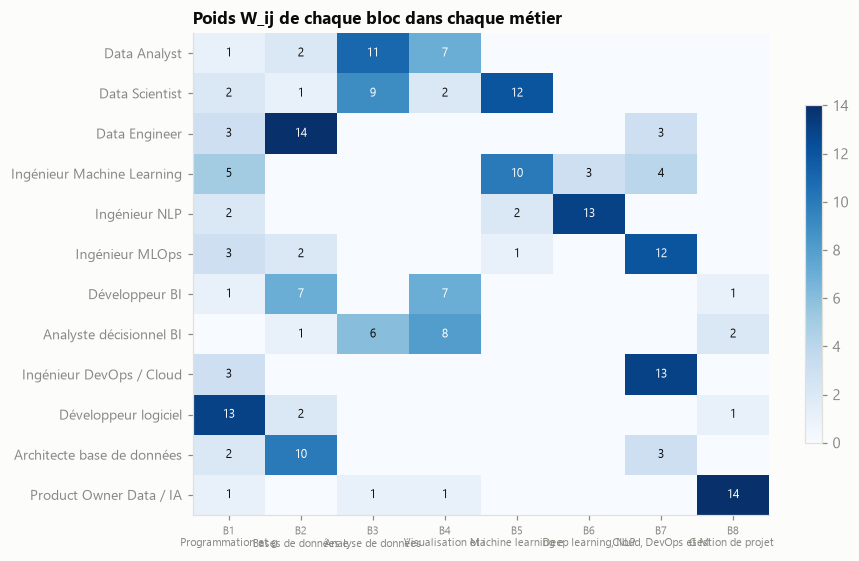

In [9]:
# Relations métiers ↔ blocs : poids W_ij = somme des poids des compétences du métier j dans le bloc i.
# Ce sont exactement les poids de la formule de couverture du sujet : Couverture_j = Σ_i W_ij·S_ij / Σ_i W_ij
W = pd.DataFrame(0.0, index=ref.metiers["metier"], columns=ref.blocs["bloc_id"])
for _, mm in ref.metiers.iterrows():
    for cid, w in ref.poids_metier(mm["metier_id"]).items():
        W.at[mm["metier"], comp.at[cid, "bloc_id"]] += w

fig, ax = plt.subplots(figsize=(8.5, 5.2))
im = ax.imshow(W.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(W.columns)), [f"{b}\n{n[:18]}" for b, n in zip(ref.blocs["bloc_id"], ref.blocs["bloc"])], fontsize=7)
ax.set_yticks(range(len(W.index)), W.index, fontsize=9)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        if W.values[i, j] > 0:
            ax.text(j, i, f"{W.values[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if W.values[i, j] > 6 else ENCRE)
ax.grid(False)
ax.set_title("Poids W_ij de chaque bloc dans chaque métier")
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()

In [10]:
# Une même compétence sert plusieurs métiers (cf. exemple « Python » du sujet)
usage = pd.Series([c for _, mm in ref.metiers.iterrows() for c in ref.poids_metier(mm["metier_id"])]).value_counts()
top = usage.head(8).rename("nb de métiers").to_frame().join(comp[["competence", "bloc"]])
display(top)

,nb de métiers,competence,bloc
C01,7,Programmation en Python,Programmation et génie logiciel
C10,7,Requêtes SQL,Bases de données et ingénierie des données
C04,5,Gestion de versions et revue de code,Programmation et génie logiciel
C26,4,Interprétation métier des résultats,Analyse de données et statistiques
C38,4,Évaluation de modèles,Machine learning et modélisation
C54,4,Conteneurisation,"Cloud, DevOps et MLOps"
C07,4,Automatisation par scripts,Programmation et génie logiciel
C11,4,Modélisation de bases de données,Bases de données et ingénierie des données


> **Interprétation.**
>
> - **Équilibre des blocs.** Les 8 blocs contiennent de 7 à 10 compétences : aucun bloc ne pèse beaucoup plus que les autres dans le radar. 55 compétences sur 71 (77 %) sont rattachées au ROME. Les 16 ajouts sont concentrés dans le bloc *Deep learning, NLP et IA générative* (9 sur 10) et dans le *Machine learning* (4 sur 9) : c'est précisément là que le ROME est le moins détaillé.
> - **Des profils de métiers distincts.** La matrice W montre que chaque métier a une « signature » : le Data Engineer pèse surtout en B2 (bases et pipelines), l'Ingénieur NLP en B6, le Product Owner en B8. Des métiers proches partagent des blocs, ce qui est réaliste et rend la tâche non triviale : Développeur BI et Analyste décisionnel partagent B4, ML Engineer et MLOps partagent B5 et B7.
> - **Des compétences partagées.** *Programmation en Python* et *Requêtes SQL* sont requises par 7 métiers sur 12. Comme dans l'exemple du sujet, un utilisateur qui décrit bien Python fait monter la couverture de tous ces métiers. Ce sont donc les compétences **spécifiques** (et leur poids « cœur ») qui départagent les métiers.

## 4. Traçabilité vers le ROME

Chaque compétence marquée « ROME enrichi » cite les codes OGR des items ROME dont elle est issue. On vérifie
ici que **tous ces codes existent** dans l'extraction officielle et qu'ils appartiennent bien à l'un des métiers
retenus.

In [11]:
codes_cites = {(cid, int(o)) for cid, s in comp["codes_ogr_rome"].items() for o in str(s).split("|") if o}
codes_extraits = set(rome_items["code_ogr"])
manquants = [(cid, o) for cid, o in codes_cites if o not in codes_extraits]
print(f"{len(codes_cites)} références ROME citées, {len(manquants)} introuvable(s) dans l'extraction officielle.")

# Quels métiers ROME alimentent le référentiel ?
lien = rome_items[rome_items["code_ogr"].isin({o for _, o in codes_cites})]
display(lien.groupby("code_rome")["code_ogr"].nunique().rename("items repris").to_frame()
        .join(rome_metiers.set_index("code_rome")["libelle_rome"]))

118 références ROME citées, 0 introuvable(s) dans l'extraction officielle.


,items repris,libelle_rome
code_rome,,
M1405,23,Data scientist
M1419,23,Data analyst
M1811,16,Data engineer
M1824,23,Développeur / Développeuse décisionnel - Business Intelligence
M1827,21,Ingénieur / Ingénieure DevOps
M1851,14,Analyste décisionnel - Business Intelligence
M1861,17,Développeur / Développeuse logiciel ou d'application
M1864,17,Product Owner
M1868,21,Architecte base de données


> **Interprétation.** Les 118 références citées existent toutes dans l'extraction officielle : chaque compétence « ROME enrichi » est vérifiable. Les 11 fiches ROME contribuent toutes, de 8 items (Ingénieur IA, fiche récente et courte) à 23 items (Data scientist, Data analyst, Développeur BI).

## 5. Vérification : les blocs sont-ils sémantiquement cohérents ?

Les blocs ont été définis à la main. Si le moteur doit calculer un score « par bloc », il faut que les compétences
d'un même bloc soient **plus proches entre elles** (au sens des embeddings) que de celles des autres blocs.
On le vérifie de deux façons avec les embeddings SBERT du moteur :

1. **Matrice de similarité** entre les 71 compétences, triées par bloc : on attend des carrés plus foncés sur la
   diagonale.
2. **Clustering** non supervisé (k-means à 8 groupes) : on mesure l'accord entre les groupes trouvés
   automatiquement et nos blocs (indice de Rand ajusté, ARI, et information mutuelle normalisée, NMI ;
   0 = hasard, 1 = accord parfait).

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Dimension des embeddings : (71, 384)
Similarité moyenne intra-bloc : 0.371 | inter-blocs : 0.274


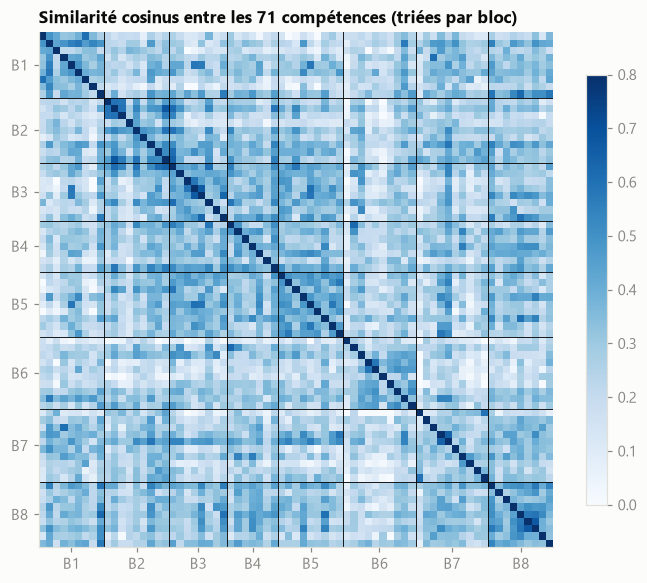

In [12]:
from src.embeddings import encodeur_sbert
enc = encodeur_sbert()
E = enc.encoder(ref.competences["texte_embedding"].tolist())   # (71, 384), lignes de norme 1
S = E @ E.T                                                   # similarité cosinus
print("Dimension des embeddings :", E.shape)

blocs = ref.competences["bloc_id"].to_numpy()
intra = np.mean([S[i, j] for i in range(len(S)) for j in range(len(S)) if i != j and blocs[i] == blocs[j]])
inter = np.mean([S[i, j] for i in range(len(S)) for j in range(len(S)) if blocs[i] != blocs[j]])
print(f"Similarité moyenne intra-bloc : {intra:.3f} | inter-blocs : {inter:.3f}")

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(S, cmap="Blues", vmin=0, vmax=0.8)
limites = np.r_[0, np.cumsum(pd.Series(blocs).value_counts(sort=False).reindex(ref.ids_blocs).values)]
for l in limites[1:-1]:
    ax.axhline(l - 0.5, color=ENCRE, lw=0.6); ax.axvline(l - 0.5, color=ENCRE, lw=0.6)
centres = (limites[:-1] + limites[1:]) / 2 - 0.5
ax.set_xticks(centres, ref.ids_blocs); ax.set_yticks(centres, ref.ids_blocs); ax.grid(False)
ax.set_title("Similarité cosinus entre les 71 compétences (triées par bloc)")
plt.colorbar(im, ax=ax, shrink=0.75); plt.tight_layout(); plt.show()

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

km = KMeans(n_clusters=8, n_init=20, random_state=0).fit(E)
print(f"ARI = {adjusted_rand_score(blocs, km.labels_):.2f} | NMI = {normalized_mutual_info_score(blocs, km.labels_):.2f}")
print(f"Silhouette des blocs manuels (cosinus) : {silhouette_score(E, blocs, metric='cosine'):.3f}")

# Table de contingence : quel cluster contient quelles compétences de chaque bloc ?
display(pd.crosstab(pd.Series(blocs, name="bloc"), pd.Series(km.labels_, name="cluster k-means")))

ARI = 0.28 | NMI = 0.49
Silhouette des blocs manuels (cosinus) : 0.023


cluster k-means,0,1,2,3,4,5,6,7
bloc,,,,,,,,
B1,0,1,8,0,0,0,0,0
B2,0,0,0,9,0,0,0,0
B3,2,1,0,2,0,0,3,0
B4,1,4,0,2,0,0,0,0
B5,7,1,0,1,0,0,0,0
B6,0,0,1,1,5,0,1,2
B7,2,2,2,2,0,2,0,0
B8,0,7,1,1,0,0,0,0


In [14]:
# Compétences dont le plus proche voisin appartient à un autre bloc : ce sont les frontières entre blocs
voisins = np.argsort(-S, axis=1)[:, 1]
frontiere = [(ref.competences.at[i, "competence"], ref.competences.at[i, "bloc_id"],
              ref.competences.at[v, "competence"], ref.competences.at[v, "bloc_id"], S[i, v])
             for i, v in enumerate(voisins) if blocs[i] != blocs[v]]
print(f"{len(frontiere)} compétences sur 71 ont leur plus proche voisin dans un autre bloc :")
display(pd.DataFrame(frontiere, columns=["compétence", "bloc", "plus proche voisin", "bloc du voisin", "cosinus"]).round(3))

32 compétences sur 71 ont leur plus proche voisin dans un autre bloc :


,compétence,bloc,plus proche voisin,bloc du voisin,cosinus
0,Développement web et API,B1,Mise en production de modèles,B7,0.460
1,Gestion de versions et revue de code,B1,Intégration et déploiement continus,B7,0.608
2,Tests logiciels,B1,Évaluation de modèles,B5,0.585
3,Documentation technique,B1,Communication avec les parties prenantes,B8,0.626
4,Orchestration de traitements,B2,Suivi des modèles et MLOps,B7,0.584
5,Qualité et gouvernance des données,B2,Nettoyage et préparation des données,B3,0.610
6,Nettoyage et préparation des données,B3,Architecture de stockage des données,B2,0.646
7,Analyse exploratoire des données,B3,Suivi des modèles et MLOps,B7,0.536
8,Prévision et séries temporelles,B3,Réseaux récurrents et séquences,B6,0.522
9,Visualisation de données,B4,Vision par ordinateur,B6,0.621


> **Interprétation.** Le résultat est **nuancé**, et instructif.
>
> - Les compétences d'un même bloc sont en moyenne plus proches entre elles (cosinus 0,371) que de celles des autres blocs (0,274). Les blocs ont donc une réalité sémantique, mais l'écart est modeste et la silhouette est proche de 0 (0,023).
> - Le k-means retrouve presque parfaitement certains blocs : B2 (9/9 dans un cluster), B1 (8/9), B5 (7/9), B8 (7/9). Il en mélange d'autres (ARI 0,28, NMI 0,49).
> - Les « erreurs » viennent surtout de **ressemblances de surface**. *Visualisation de données* a pour plus proche voisin *Vision par ordinateur*, sans doute parce que les deux parlent de produire ou d'analyser des images. *Tableaux de bord* et *Reporting* se rapprochent de *Supervision et monitoring* (suivre des indicateurs). *Prévision et séries temporelles* se rapproche des *Réseaux récurrents* (séquences).
>
> **Conséquence pour le moteur.** Les blocs restent une organisation **métier** définie par des humains : ce sont eux qui structurent le radar et la formule de couverture. En revanche, l'appariement sémantique se fait **compétence par compétence**, jamais au niveau d'un bloc entier. Un embedding moyen par bloc serait flou, puisque les blocs ne forment pas des nuages bien séparés. Ce choix est mesuré dans le notebook 03 (agrégation « par bloc » du pseudocode du sujet contre agrégation « par compétence »).

## 6. Prétraitement des textes

Deux niveaux de prétraitement sont utilisés (code : `src/preprocessing.py`).

**Pour SBERT (le moteur), un prétraitement léger** : normalisation des apostrophes et des espaces, découpage en
phrases puis en propositions autour des connecteurs d'opposition (« mais », « cependant »…), et détection des
propositions négatives. On ne supprime **pas** les mots vides et on ne lemmatise **pas** : SBERT a été entraîné sur
des phrases naturelles, et « je n'ai **jamais** fait » ou « **sans** expérience » sont justement des mots vides
qui changent le sens.

**Pour les méthodes de comparaison (TF-IDF, embeddings de mots), un prétraitement lourd** : minuscules,
lemmatisation et suppression des mots vides avec spaCy, sinon « nettoyer », « nettoyé » et « nettoyage »
seraient trois mots sans rapport.

In [15]:
from src.preprocessing import decouper_unites, est_negative, pretraiter_lexical

texte = ("En stage, j’ai automatisé le reporting mensuel avec Python et Power BI, mais je n'ai jamais "
         "déployé de modèle en production. J'aime beaucoup expliquer les résultats aux équipes métier !")
for u in decouper_unites(texte):
    print(f"{'NÉGATIVE ' if est_negative(u) else 'positive '} | {u}")
print("\nVersion lexicale (TF-IDF) :", pretraiter_lexical(texte))

positive  | En stage, j'ai automatisé le reporting mensuel avec Python et Power BI
NÉGATIVE  | je n'ai jamais déployé de modèle en production
positive  | J'aime beaucoup expliquer les résultats aux équipes métier



Version lexicale (TF-IDF) : stage automatiser reporting mensuel python power bi jamais déployer modèle production aimer beaucoup expliquer résultat équipe métier


> **Interprétation.** Le texte est découpé en trois propositions et la deuxième est correctement détectée comme négative : elle ne sera pas utilisée comme preuve de la compétence *Mise en production de modèles*. Sans ce découpage, la phrase entière (« j'ai automatisé le reporting… **mais** je n'ai jamais déployé… ») aurait été soit gardée, et la négation aurait gonflé le score de déploiement, soit rejetée, et l'expérience de reporting aurait été perdue. La version lexicale montre ce que voit TF-IDF : des lemmes sans ordre, où « jamais » n'est qu'un mot parmi d'autres.

## Conclusion

- Le référentiel contient **8 blocs, 71 compétences et 12 métiers**. Il est construit à partir du **ROME 4.0**, et
  chaque compétence issue du ROME est traçable jusqu'aux items officiels.
- Chaque compétence est décrite par **une phrase en langage naturel**, ce qui donne au moteur une cible
  sémantique riche plutôt qu'un simple mot-clé.
- Les métiers sont reliés aux compétences avec des **poids** (cœur = 2, secondaire = 1). Ces poids alimentent
  directement la formule de couverture du sujet.
- Les blocs sont **sémantiquement cohérents**, avec des frontières naturelles entre blocs voisins (BI et analyse,
  ML et deep learning). Le notebook 02 montre comment ces données sont utilisées par le moteur.